# 03 — Own-history vs Spatio-temporal models (LogReg, LightGBM)
**Task:** at decision time τ, for each oblast, predict **P(alert starts within the next h)**, h ∈ {15, 30, 60} min.

**Main question (ablation):** does information about *other* oblasts improve on the oblast's *own* history?

| Model | Features |
|---|---|
| Climatology | oblast × hour (train) |
| sNaive-mean 7×1d | best sNaive from notebook 02 |
| LogReg-own | own history + calendar + oblast |
| LightGBM-own | own history + calendar + oblast |
| **LightGBM-spatial** | + number of oblasts on alert, attack-wave dynamics, lift-weighted neighbours, top-3 early-warning neighbours |

**Leakage protocol:** features from `src/features.py` (only trailing operations, verified by `tests/test_leakage.py`); the neighbour graph (lift) is estimated on **train only**; early stopping on **validation**; test used once.

In [1]:
import json, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

sys.path.insert(0, str(Path.cwd()))
from src.features import (build_features, build_targets, compute_lift, future_starts,
                          HORIZONS, OWN, CAL, SPATIAL, nbr_cols, STEP)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
DATA_DIR = Path("data")

state  = pd.read_parquet(DATA_DIR / "state_5min.parquet")
starts = pd.read_parquet(DATA_DIR / "starts_5min.parquet")
split  = {k: pd.Timestamp(v) for k, v in json.loads((DATA_DIR / "split.json").read_text()).items()}
VAL, TEST = split["val_start"], split["test_start"]
TRAIN_START = VAL - pd.Timedelta(days=365)        # recent year only: tactics drift

# keep only what is needed (+ margin for 24h / 7d look-backs)
lo = TRAIN_START - pd.Timedelta(days=10)
state, starts = state.loc[lo:], starts.loc[lo:]
oblasts = list(state.columns)
print(state.shape, "| train", TRAIN_START.date(), "→", VAL.date(), "| val →", TEST.date(), "| test →", state.index[-1])

(125385, 24) | train 2025-07-09 → 2026-07-09 | val → 2026-08-08 | test → 2026-09-07 08:40:00+03:00


## 1. Neighbour graph (lift) — train only

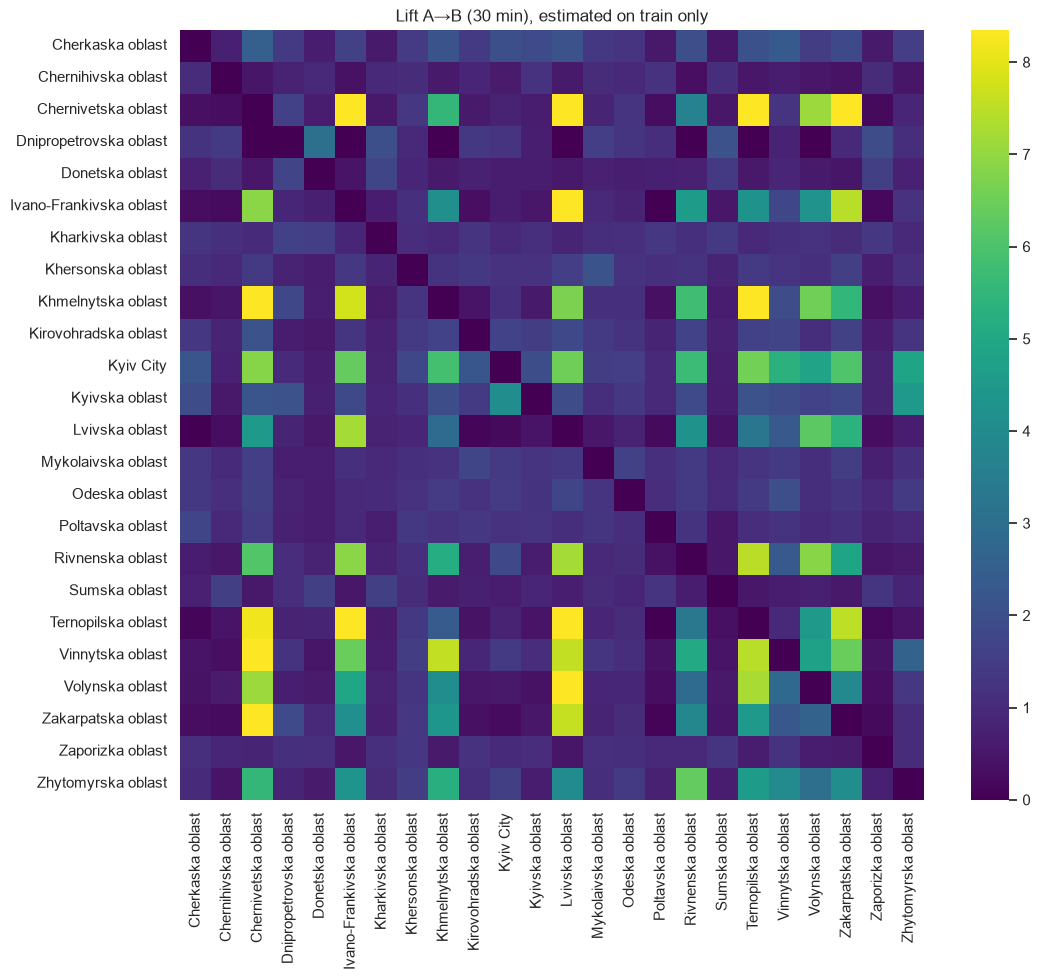

Kyivska oblast          4.08
Cherkaska oblast        2.00
Rivnenska oblast        1.82
Kirovohradska oblast    1.65
Zhytomyrska oblast      1.56
Name: Kyiv City, dtype: float64

In [2]:
lift = compute_lift(starts, VAL)
plt.figure(figsize=(12, 10))
sns.heatmap(lift, cmap="viridis", vmax=np.quantile(lift.values, .98))
plt.title("Lift A→B (30 min), estimated on train only"); plt.show()
lift["Kyiv City"].nlargest(5).round(2)

## 2. Samples
- train: every 15 min (to limit size), val/test: every 5 min.
- The last 60 min before each boundary are dropped so that **targets never cross into the next period**.

In [3]:
gap = pd.Timedelta("60min")
idx = state.index
t_train = idx[(idx >= TRAIN_START) & (idx < VAL  - gap)][::3]
t_val   = idx[(idx >= VAL)         & (idx < TEST - gap)]
t_test  = idx[(idx >= TEST)        & (idx < idx[-1] - gap)]

t0 = time.time()
sets = {}
for name, t in {"train": t_train, "val": t_val, "test": t_test}.items():
    X = build_features(state, starts, lift, t)
    Y = build_targets(starts, t)
    sets[name] = (X, Y)
    print(f"{name:5s}: {X.shape}, positives 30min = {Y['y_30min'].mean():.3f}")
print(f"{time.time()-t0:.0f}s")

train: (840864, 28), positives 30min = 0.047


val  : (207072, 28), positives 30min = 0.064


test : (209568, 28), positives 30min = 0.061
3s


In [4]:
FRONT = (state.loc[TRAIN_START:VAL].mean() > 0.25).pipe(lambda s: s[s].index.tolist())   # train only
REAR  = [o for o in oblasts if o not in FRONT]

FEATS_OWN     = OWN + CAL
FEATS_SPATIAL = OWN + CAL + SPATIAL + nbr_cols()
print(len(FEATS_OWN), "own features;", len(FEATS_SPATIAL), "spatial features")
sets["train"][0][FEATS_SPATIAL].describe().T.round(2)

11 own features; 28 spatial features


,count,mean,std,min,25%,50%,75%,max
on_now,840864.0,0.27,0.44,0.0,0.00,0.00,1.00,1.00
since_start,840864.0,359.29,506.09,0.0,38.00,127.00,458.00,2016.00
since_on,840864.0,289.53,471.89,0.0,0.00,65.00,356.00,2016.00
starts_1h,840864.0,0.10,0.30,0.0,0.00,0.00,0.00,4.00
starts_6h,840864.0,0.57,0.88,0.0,0.00,0.00,1.00,8.00
starts_24h,840864.0,2.29,2.51,0.0,0.00,1.00,4.00,17.00
share_on_24h,840864.0,0.27,0.34,0.0,0.00,0.10,0.45,1.00
hour_sin,840864.0,0.00,0.71,-1.0,-0.72,0.02,0.72,1.00
hour_cos,840864.0,-0.00,0.71,-1.0,-0.72,-0.02,0.69,1.00
dow,840864.0,3.00,2.00,0.0,1.00,3.00,5.00,6.00


## 3. Models

In [5]:
def add_oblast(X):
    X = X.copy(); X["oblast"] = pd.Categorical(X.index.get_level_values("oblast"), categories=oblasts)
    return X

def fit_lgb(feats, h):
    (Xtr, Ytr), (Xva, Yva) = sets["train"], sets["val"]
    params = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_data_in_leaf=300,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, seed=0)
    dtr = lgb.Dataset(add_oblast(Xtr)[feats + ["oblast"]], Ytr[f"y_{h}"])
    dva = lgb.Dataset(add_oblast(Xva)[feats + ["oblast"]], Yva[f"y_{h}"], reference=dtr)
    return lgb.train(params, dtr, 3000, valid_sets=[dva],
                     callbacks=[lgb.early_stopping(150, verbose=False)])

def fit_logreg(feats, h):
    Xtr, Ytr = sets["train"]
    X = Xtr[feats].copy(); X[["since_start", "since_on"]] = np.log1p(X[["since_start", "since_on"]])
    X["oblast"] = X.index.get_level_values("oblast")
    ct = ColumnTransformer([("num", StandardScaler(), feats),
                            ("cat", OneHotEncoder(handle_unknown="ignore"), ["oblast"])])
    m = make_pipeline(ct, LogisticRegression(max_iter=2000, C=1.0))
    m.fit(X, Ytr[f"y_{h}"])
    return m

def predict_logreg(m, X, feats):
    X = X[feats].copy(); X[["since_start", "since_on"]] = np.log1p(X[["since_start", "since_on"]])
    X["oblast"] = X.index.get_level_values("oblast")
    return m.predict_proba(X)[:, 1]

def climatology(h, X):
    Xtr, Ytr = sets["train"]
    tr = Ytr[f"y_{h}"].groupby([Xtr.index.get_level_values("oblast"),
                                (Xtr.index.get_level_values("time") + STEP).hour]).mean()
    key = pd.MultiIndex.from_arrays([X.index.get_level_values("oblast"),
                                     (X.index.get_level_values("time") + STEP).hour])
    return tr.reindex(key).values

def snaive_mean(h, X, K=7):
    Yh = future_starts(starts, HORIZONS[h])
    day = int(pd.Timedelta("1D") / STEP)
    P = sum(Yh.shift(m * day) for m in range(1, K + 1)) / K
    t = X.index.get_level_values("time").unique()
    return P.loc[t].stack(future_stack=True).reindex(X.index).values

In [6]:
preds, models = {}, {}
for h in HORIZONS:
    t0 = time.time()
    m_lr  = fit_logreg(FEATS_OWN, h)
    m_own = fit_lgb(FEATS_OWN, h)
    m_sp  = fit_lgb(FEATS_SPATIAL, h)
    models[h] = {"LogReg-own": m_lr, "LightGBM-own": m_own, "LightGBM-spatial": m_sp}
    for part in ["val", "test"]:
        X, Y = sets[part]
        preds[(h, part)] = pd.DataFrame({
            "y": Y[f"y_{h}"].values,
            "Climatology": climatology(h, X),
            "sNaive-mean 7×1d": snaive_mean(h, X),
            "LogReg-own": predict_logreg(m_lr, X, FEATS_OWN),
            "LightGBM-own": m_own.predict(add_oblast(X)[FEATS_OWN + ["oblast"]]),
            "LightGBM-spatial": m_sp.predict(add_oblast(X)[FEATS_SPATIAL + ["oblast"]]),
        }, index=X.index)
    print(f"{h}: own iters={m_own.best_iteration}, spatial iters={m_sp.best_iteration}, {time.time()-t0:.0f}s")

15min: own iters=257, spatial iters=401, 37s


30min: own iters=250, spatial iters=324, 26s


60min: own iters=219, spatial iters=365, 23s


## 4. Results

In [7]:
MODELS = ["Climatology", "sNaive-mean 7×1d", "LogReg-own", "LightGBM-own", "LightGBM-spatial"]

def scores(P, cols=None):
    if cols is not None: P = P[P.index.get_level_values("oblast").isin(cols)]
    P = P.dropna()
    return pd.DataFrame({m: {"PR-AUC": average_precision_score(P.y, P[m]),
                             "ROC-AUC": roc_auc_score(P.y, P[m]),
                             "Brier": brier_score_loss(P.y, P[m].clip(0, 1))} for m in MODELS}).T.assign(base_rate=P.y.mean())

rows = []
for (h, part), P in preds.items():
    for grp, cols in {"all": None, "rear": REAR, "frontline": FRONT}.items():
        rows.append(scores(P, cols).assign(horizon=h, period=part, group=grp).rename_axis("model").reset_index())
res = pd.concat(rows)

for grp in ["rear", "frontline", "all"]:
    print(f"\n=== PR-AUC — TEST — {grp} ===")
    print(res.query("period=='test' and group==@grp").pivot(index="model", columns="horizon", values="PR-AUC")
             .loc[MODELS, list(HORIZONS)].round(3))


=== PR-AUC — TEST — rear ===
horizon           15min  30min  60min
model                                
Climatology       0.073  0.144  0.273
sNaive-mean 7×1d  0.040  0.095  0.210
LogReg-own        0.131  0.233  0.384
LightGBM-own      0.133  0.235  0.390
LightGBM-spatial  0.148  0.240  0.371

=== PR-AUC — TEST — frontline ===
horizon           15min  30min  60min
model                                
Climatology       0.060  0.116  0.218
sNaive-mean 7×1d  0.049  0.107  0.217
LogReg-own        0.249  0.354  0.458
LightGBM-own      0.260  0.370  0.455
LightGBM-spatial  0.264  0.375  0.485

=== PR-AUC — TEST — all ===
horizon           15min  30min  60min
model                                
Climatology       0.060  0.118  0.223
sNaive-mean 7×1d  0.043  0.098  0.211
LogReg-own        0.193  0.295  0.418
LightGBM-own      0.198  0.302  0.416
LightGBM-spatial  0.209  0.312  0.433


In [8]:
print("=== ROC-AUC and Brier — TEST — rear ===")
res.query("period=='test' and group=='rear'").pivot(index="model", columns="horizon", values=["ROC-AUC", "Brier"]).loc[MODELS].round(4)

=== ROC-AUC and Brier — TEST — rear ===


ROC-AUC                   Brier                
horizon            15min   30min   60min   15min   30min   60min
model                                                           
Climatology       0.7985  0.8052  0.8182  0.0235  0.0446  0.0783
sNaive-mean 7×1d  0.6070  0.6636  0.7275  0.0264  0.0492  0.0838
LogReg-own        0.8602  0.8562  0.8597  0.0225  0.0415  0.0706
LightGBM-own      0.8644  0.8626  0.8666  0.0226  0.0417  0.0707
LightGBM-spatial  0.8929  0.8839  0.8762  0.0222  0.0408  0.0693

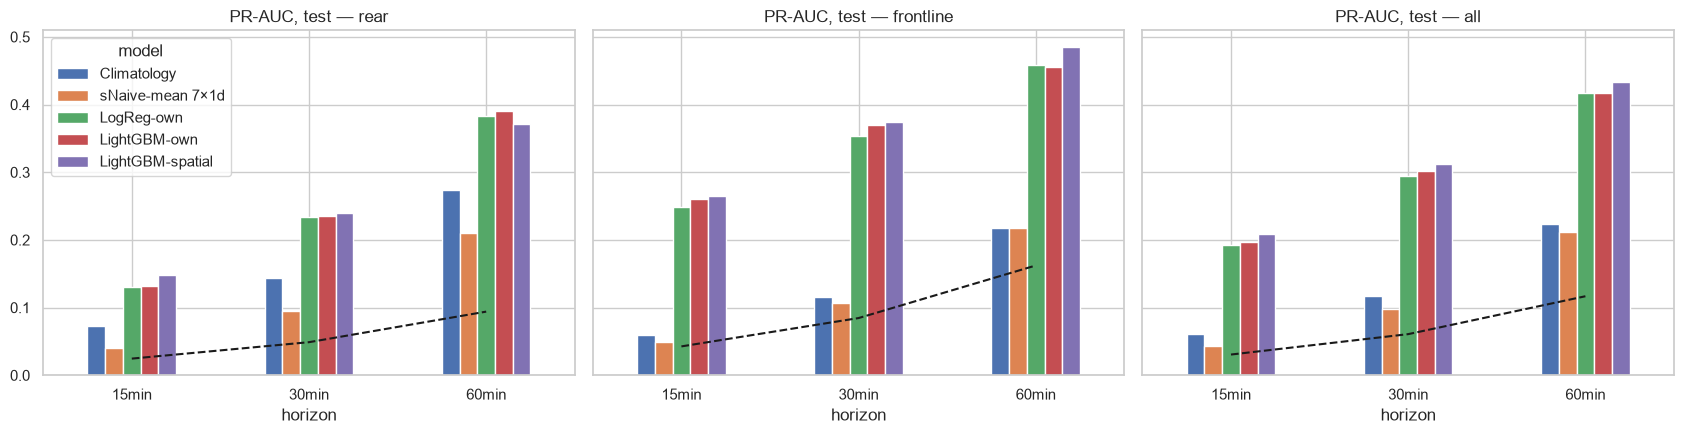

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for a, grp in zip(ax, ["rear", "frontline", "all"]):
    t = res.query("period=='test' and group==@grp").pivot(index="horizon", columns="model", values="PR-AUC").loc[list(HORIZONS), MODELS]
    t.plot(kind="bar", ax=a, rot=0, legend=(grp == "rear"), title=f"PR-AUC, test — {grp}")
    base = res.query("period=='test' and group==@grp").groupby("horizon")["base_rate"].first().loc[list(HORIZONS)]
    a.plot(range(3), base.values, "k--")
plt.tight_layout(); plt.show()

## 5. Significance: block bootstrap by day
Is LightGBM-spatial really better than LightGBM-own? Resample whole days (alerts within a day are correlated).

In [10]:
def bootstrap_diff(P, a, b, cols=REAR, n=300, seed=0):
    P = P[P.index.get_level_values("oblast").isin(cols)].dropna()
    days = P.index.get_level_values("time").normalize()
    groups = {d: np.where(days == d)[0] for d in days.unique()}
    keys = list(groups); rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        ix = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])
        s = P.iloc[ix]
        out.append(average_precision_score(s.y, s[a]) - average_precision_score(s.y, s[b]))
    return np.percentile(out, [2.5, 50, 97.5])

for h in HORIZONS:
    lo_, med, hi_ = bootstrap_diff(preds[(h, "test")], "LightGBM-spatial", "LightGBM-own")
    print(f"{h}: ΔPR-AUC (spatial − own), rear = {med:+.3f}  [95% CI {lo_:+.3f}, {hi_:+.3f}]")

15min: ΔPR-AUC (spatial − own), rear = +0.016  [95% CI +0.004, +0.030]


30min: ΔPR-AUC (spatial − own), rear = +0.005  [95% CI -0.008, +0.019]


60min: ΔPR-AUC (spatial − own), rear = -0.017  [95% CI -0.034, -0.003]


## 6. Per-oblast gain (h = 30 min, test)

In [11]:
P = preds[("30min", "test")]
per = []
for o, g in P.groupby(level="oblast"):
    if g.y.sum() < 5: continue
    per.append({"oblast": o, "group": "front" if o in FRONT else "rear", "positives": int(g.y.sum()),
                "base": g.y.mean(),
                "Climatology": average_precision_score(g.y, g["Climatology"]),
                "LightGBM-own": average_precision_score(g.y, g["LightGBM-own"]),
                "LightGBM-spatial": average_precision_score(g.y, g["LightGBM-spatial"])})
per = pd.DataFrame(per).set_index("oblast")
per["gain spatial vs own"] = per["LightGBM-spatial"] - per["LightGBM-own"]
per.sort_values("gain spatial vs own", ascending=False).round(3)

,group,positives,base,Climatology,LightGBM-own,LightGBM-spatial,gain spatial vs own
oblast,,,,,,,
Kyiv City,rear,574,0.066,0.071,0.173,0.327,0.155
Ternopilska oblast,rear,42,0.005,0.006,0.007,0.108,0.101
Cherkaska oblast,rear,615,0.070,0.080,0.143,0.240,0.097
Volynska oblast,rear,42,0.005,0.008,0.012,0.105,0.093
Rivnenska oblast,rear,108,0.012,0.015,0.023,0.096,0.073
Khmelnytska oblast,rear,120,0.014,0.013,0.032,0.095,0.063
Kirovohradska oblast,rear,828,0.095,0.096,0.141,0.190,0.049
Kharkivska oblast,front,762,0.087,0.119,0.379,0.413,0.035
Chernivetska oblast,rear,30,0.003,0.005,0.010,0.043,0.033


## 7. What does the spatial model use?

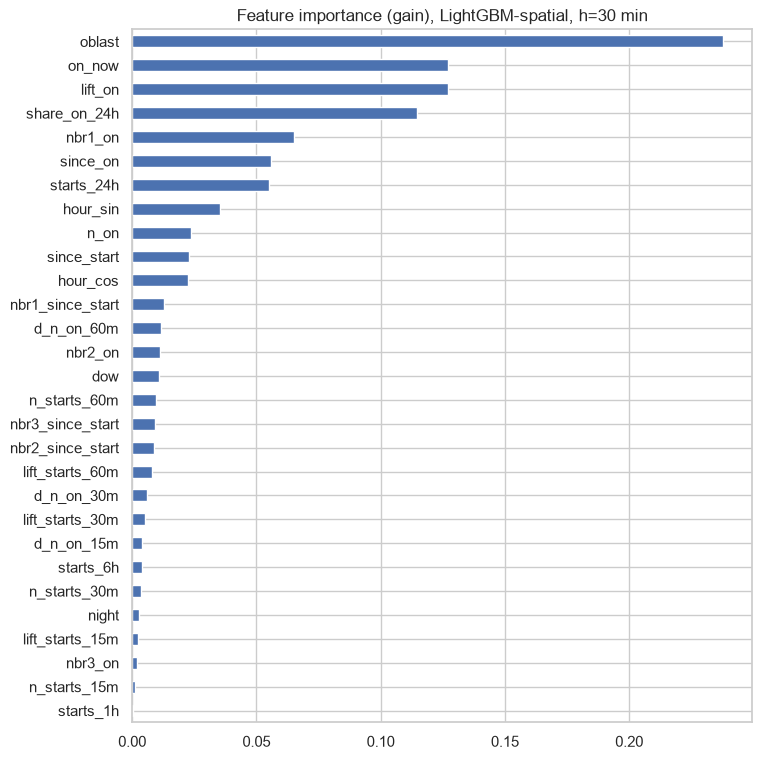

In [12]:
m = models["30min"]["LightGBM-spatial"]
imp = pd.Series(m.feature_importance("gain"), index=m.feature_name()).sort_values()
(imp / imp.sum()).plot.barh(figsize=(8, 9), title="Feature importance (gain), LightGBM-spatial, h=30 min")
plt.show()

## 8. Calibration (h = 30 min, test, rear)

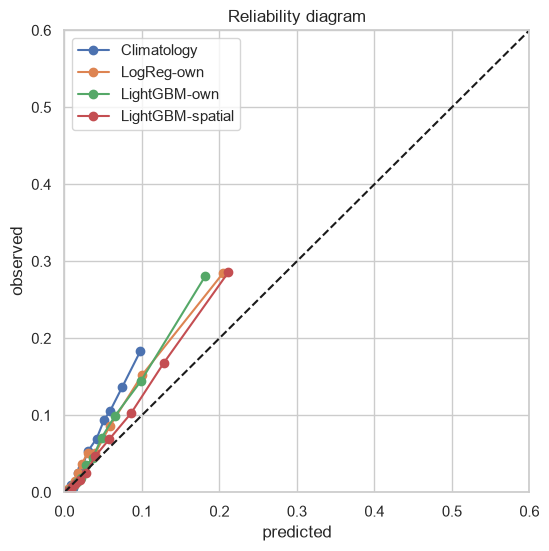

In [13]:
P = preds[("30min", "test")]; P = P[P.index.get_level_values("oblast").isin(REAR)]
plt.figure(figsize=(6, 6))
for mname in ["Climatology", "LogReg-own", "LightGBM-own", "LightGBM-spatial"]:
    fy, fx = calibration_curve(P.y, P[mname], n_bins=15, strategy="quantile")
    plt.plot(fx, fy, "o-", label=mname)
plt.plot([0, 1], [0, 1], "k--"); plt.xlim(0, .6); plt.ylim(0, .6)
plt.xlabel("predicted"); plt.ylabel("observed"); plt.legend(); plt.title("Reliability diagram")
plt.show()

## 9. Case study: Kyiv City, busiest test day

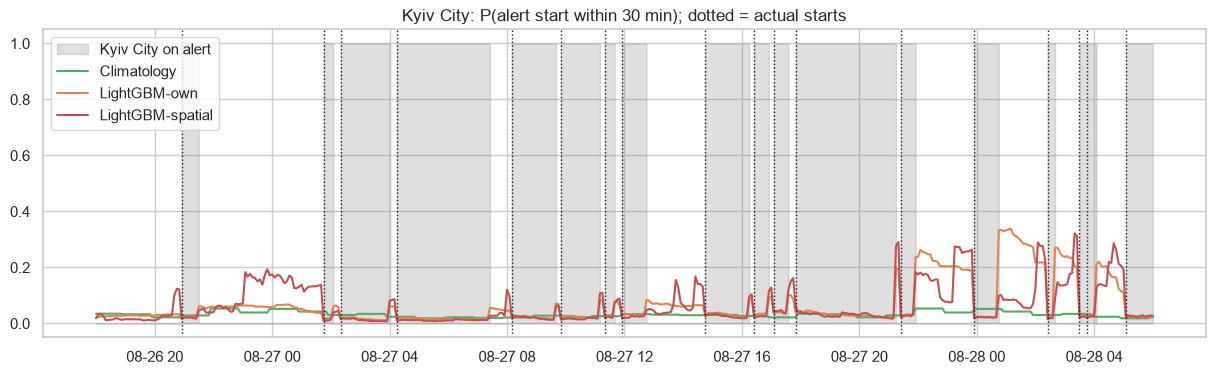

In [14]:
o = "Kyiv City"
P = preds[("30min", "test")].xs(o, level="oblast")
day = P.y.resample("D").sum().idxmax()
w = P.loc[day - pd.Timedelta("6h"): day + pd.Timedelta("30h")]
st = state.loc[w.index, o]
fig, ax = plt.subplots(figsize=(15, 4))
ax.fill_between(st.index, st, step="post", color="grey", alpha=.25, label="Kyiv City on alert")
for mname, c in [("Climatology", "C2"), ("LightGBM-own", "C1"), ("LightGBM-spatial", "C3")]:
    ax.plot(w.index, w[mname], c=c, label=mname)
for t in starts.loc[w.index].index[starts.loc[w.index, o] == 1]:
    ax.axvline(t, c="k", lw=1, ls=":")
ax.set_title(f"{o}: P(alert start within 30 min); dotted = actual starts"); ax.legend(loc="upper left")
plt.show()

## 10. Early warning: how many minutes before the official alert?

In [15]:
# Threshold chosen on VALIDATION at precision ≈ 0.5 for rear oblasts, then applied to test
from sklearn.metrics import precision_recall_curve
def threshold_at_precision(P, m, target=0.5):
    P = P[P.index.get_level_values("oblast").isin(REAR)].dropna()
    pr, rc, th = precision_recall_curve(P.y, P[m])
    ok = np.where(pr[:-1] >= target)[0]
    return th[ok[0]] if len(ok) else th[-1]

h = "60min"
rows = []
for mname in ["LightGBM-own", "LightGBM-spatial"]:
    thr = threshold_at_precision(preds[(h, "val")], mname)
    P = preds[(h, "test")]
    for o in REAR:
        p = P[mname].xs(o, level="oblast")
        s_times = starts.loc[TEST:, o]; s_times = s_times[s_times == 1].index
        for ts in s_times:
            win = p.loc[ts - pd.Timedelta("60min"): ts - STEP]        # forecasts made before the start
            hit = win[win >= thr]
            rows.append({"model": mname, "oblast": o, "warned": len(hit) > 0,
                         "lead_min": (ts - hit.index[0] - STEP).total_seconds() / 60 if len(hit) else np.nan})
ew = pd.DataFrame(rows)
ew.groupby("model").agg(share_warned=("warned", "mean"), median_lead_min=("lead_min", "median")).round(2)

,share_warned,median_lead_min
model,,
LightGBM-own,0.23,50.0
LightGBM-spatial,0.20,35.0


In [16]:
res.to_csv(DATA_DIR / "results_03_models.csv", index=False)
print("saved")

saved


## Conclusions (fill in after running)
- Spatial vs own-history: …
- Gain is largest for: …
- Most important features: …
- Early warning: …
- Next: Hawkes model (interpretable propagation graph), Telegram features.